In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/justinwshj/football-players/football-players-detection/README.dataset.txt
/kaggle/input/datasets/justinwshj/football-players/football-players-detection/README.roboflow.txt
/kaggle/input/datasets/justinwshj/football-players/football-players-detection/data.yaml
/kaggle/input/datasets/justinwshj/football-players/football-players-detection/test/images/08fd33_3_6_png.rf.bee65249830b3e263ebe95a999f39e34.jpg
/kaggle/input/datasets/justinwshj/football-players/football-players-detection/test/images/08fd33_9_3_png.rf.f5439a0d252bbf8a8ce96169744b49b6.jpg
/kaggle/input/datasets/justinwshj/football-players/football-players-detection/test/images/40cd38_7_6_png.rf.dc7957fcce915bc48188f18a7b19455b.jpg
/kaggle/input/datasets/justinwshj/football-players/football-players-detection/test/images/42ba34_1_5_png.rf.927d602c034ce2997f58f62a7c1245ba.jpg
/kaggle/input/datasets/justinwshj/football-players/football-players-detection/test/images/42ba34_5_5_png.rf.f691b18c36a92663c7241c99d4202

# 模型训练和预测

In [2]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 7.4 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics] [ultralytics]


In [3]:
from ultralytics import YOLO 

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [5]:
model = YOLO("yolo11n.pt")

In [7]:
# 采用 CLI 方式进行模型训练
!yolo task = detect \
    mode = train \
    model = yolo11n.pt \
    data = /kaggle/input/datasets/justinwshj/football-players/football-players-detection/data.yaml \
    epochs = 50 \
    imgsz = 800 \
    plots = True \
    device = 0,1

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/input/datasets/justinwshj/football-players/football-players-detection/data.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=800, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup

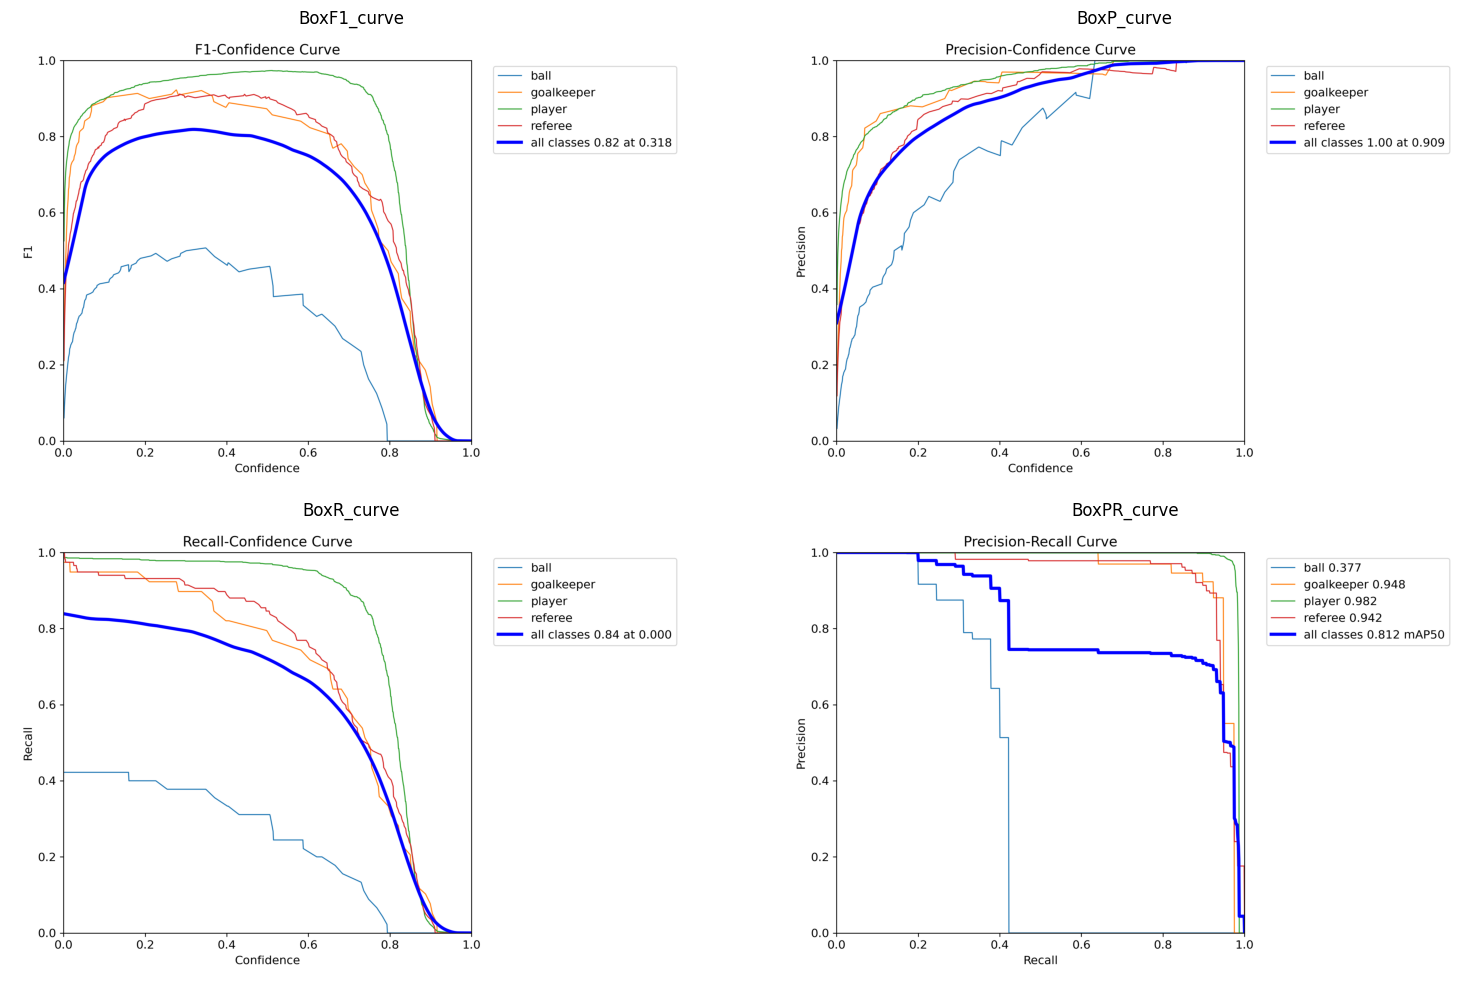

In [14]:
import matplotlib
import matplotlib.pyplot as plt

# 指定性能评估曲线的图片所在的目录
directory = '/kaggle/working/runs/detect/train'

# 定义要展示的图片文件名
image_files = [
    "BoxF1_curve.png",
    "BoxP_curve.png",
    "BoxR_curve.png",
    "BoxPR_curve.png"
]

# 创建一个包含 4 个子图的图形
fig, axes = plt.subplots(2, 2, figsize = (16, 10))
axes = axes.flatten() # 将二维数组展平为一维数组以便于索引

# 遍历每个图片文件并加载到相应的子图中
for ax, image_file in zip(axes, image_files):
    image_path = os.path.join(directory, image_file)
    if os.path.exists(image_path):
        img = plt.imread(image_path)
        ax.imshow(img)
        ax.set_title(os.path.splitext(image_file)[0]) # 设置子标题为图片文件名（去掉扩展名）
        ax.axis('off') # 关闭坐标轴
    else:
        ax.text(0.5, 0.5, f"File not found: {image_file}", ha = 'center', va = 'center', fontsize = 12)
        ax.axis('off')

# 调整子网间距
plt.tight_layout()
plt.show()

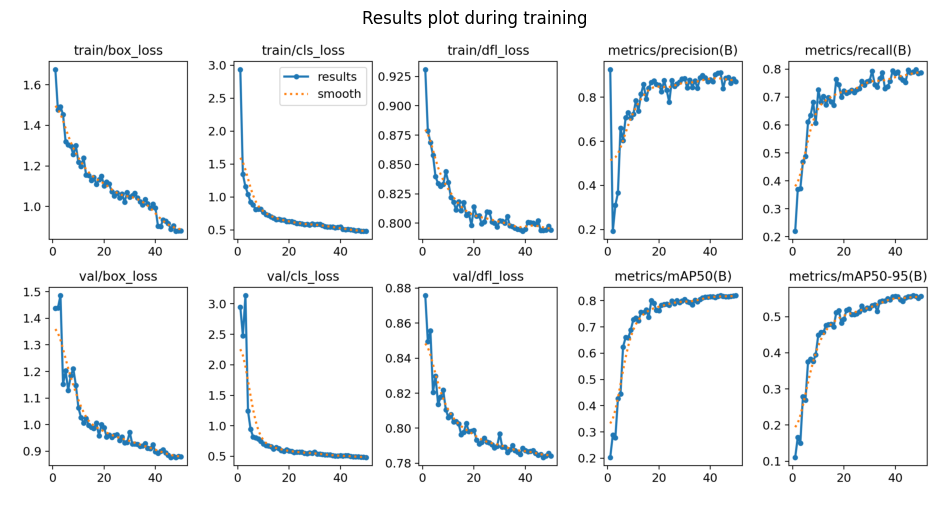

In [16]:
# result.png 图片路径
image_path = '/kaggle/working/runs/detect/train/results.png'

# 读取图片
img = plt.imread(image_path)
# 创建一个图形窗口并显示图片
plt.figure(figsize = (12, 8))
plt.imshow(img)
plt.title("Results plot during training")
plt.axis('off')
plt.show()

In [17]:
!yolo task = detect \
    mode = val \
    model = /kaggle/working/runs/detect/train/weights/best.pt \
    data = /kaggle/input/datasets/justinwshj/football-players/football-players-detection/data.yaml

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.1 ms, read: 285.2±44.5 MB/s, size: 156.7 KB)
val: Scanning /kaggle/input/datasets/justinwshj/football-players/football-players-detection/valid/labels... 49 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 49/49 763.4it/s 0.1s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/justinwshj/football-players/football-players-detection/valid is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.0it/s 2.0s0.8s
                   all         49       1174        0.9       0.79      0.816       0.56
                  ball         45         45      0.824      0.378      0.392      0.182
            goalkeeper         38         39      0.937      0.897      0.948      0.681
                play

In [18]:
# 使用 yolo 模型进行目标预测
!yolo task = detect \
    mode = predict \
    model = /kaggle/working/runs/detect/train/weights/best.pt \
    conf = 0.25 \
    source = /kaggle/input/datasets/justinwshj/football-players/football-players-detection/test/images \
    save = True

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs

image 1/25 /kaggle/input/datasets/justinwshj/football-players/football-players-detection/test/images/08fd33_3_6_png.rf.bee65249830b3e263ebe95a999f39e34.jpg: 800x800 1 ball, 20 players, 2 referees, 15.8ms
image 2/25 /kaggle/input/datasets/justinwshj/football-players/football-players-detection/test/images/08fd33_9_3_png.rf.f5439a0d252bbf8a8ce96169744b49b6.jpg: 800x800 21 players, 1 referee, 15.7ms
image 3/25 /kaggle/input/datasets/justinwshj/football-players/football-players-detection/test/images/40cd38_7_6_png.rf.dc7957fcce915bc48188f18a7b19455b.jpg: 800x800 1 goalkeeper, 20 players, 2 referees, 15.7ms
image 4/25 /kaggle/input/datasets/justinwshj/football-players/football-players-detection/test/images/42ba34_1_5_png.rf.927d602c034ce2997f58f62a7c1245ba.jpg: 800x800 1 ball, 1 goalkeeper, 22 players, 2 referees, 15.7ms
image

In [19]:
# 随机选择 4 张预测的图片
predict_path = '/kaggle/working/runs/detect/predict'
predict_image_files = [f for f in os.listdir(predict_path) if f.endswith('.jpg')]
predict_image_file = np.random.choice(predict_image_files, 4)

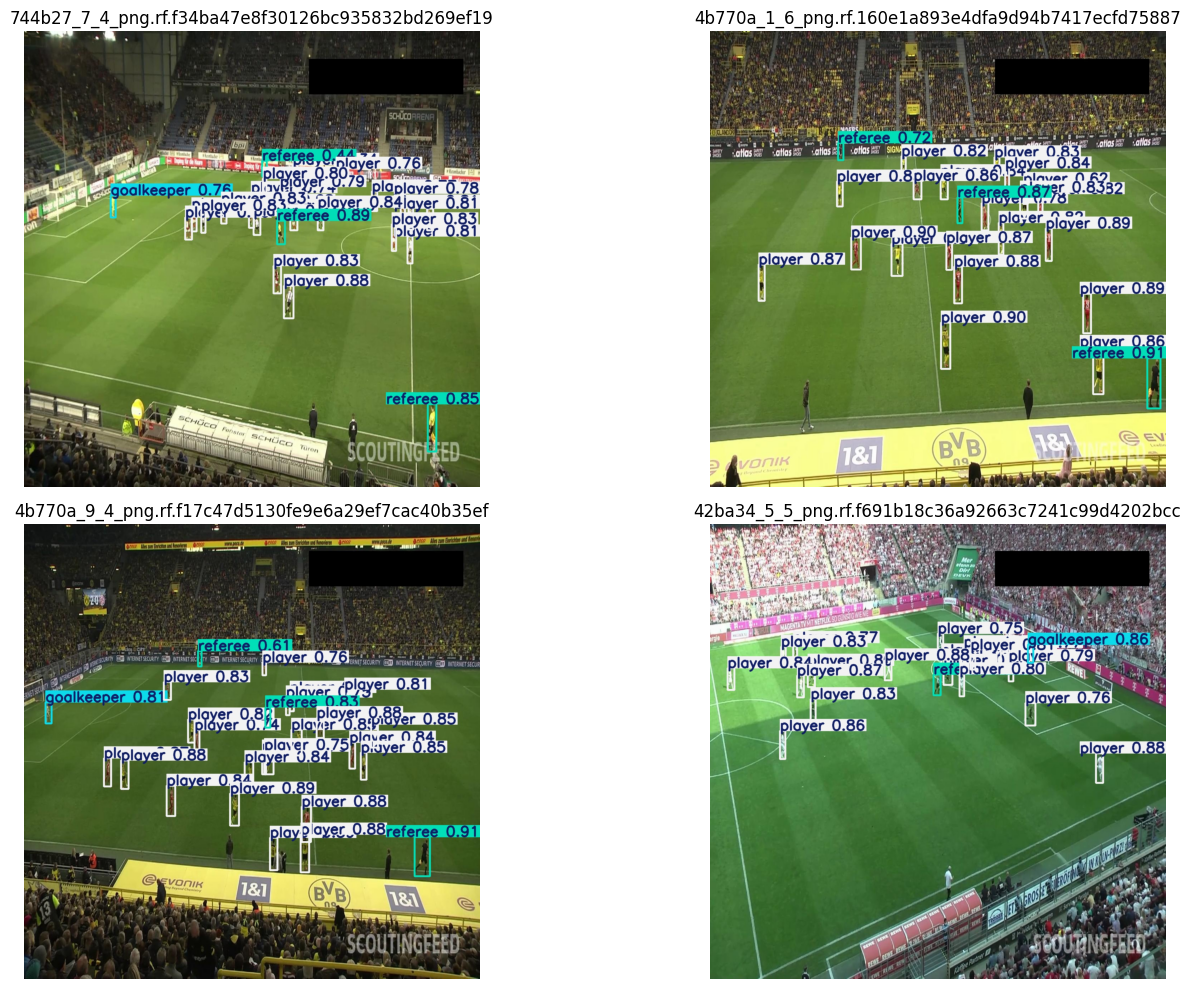

In [20]:
# 创建一个包含 4 个子图的图形
fig, axes = plt.subplots(2, 2, figsize = (16, 10))
axes = axes.flatten()

# 遍历每个图片文件并加载到相应的子图中
for ax, image_file in zip(axes, predict_image_file):
    image_path = os.path.join(predict_path, image_file)
    if os.path.exists(image_path):
        image = plt.imread(image_path)
        ax.imshow(image)
        ax.set_title(os.path.splitext(image_file)[0])
        ax.axis('off')
    else:
        ax.text(0.5, 0.5, f"File not found: {image_file}", ha = 'center', va = 'center', fontsize = 12)
        ax.axis('off')

# 调整子图间距
plt.tight_layout()
plt.show()

In [21]:
!zip -q -r results.zip /kaggle/working/*